# 04 商品结构（MySQL + Python 可视化）

**数据源**：MySQL `olist`
**分析逻辑**：执行 `analysis_code/04_commodity_structure.sql`（4 条查询）
**口径**：品类销售额 = 有效订单的 `price` 之和（**不含运费**，区别于 03 的 GMV）


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 找到项目根（含 analysis_code/ 的目录），兼容从 notebooks/ 或项目根启动
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "analysis_code").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks"))
import db

# 先设 seaborn 主题，再设中文字体（顺序不能反）
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

print("project root:", PROJECT_ROOT)
print("sql dir:", db.SQL_DIR)

project root: C:\Users\iiLI\Desktop\1
sql dir: C:\Users\iiLI\Desktop\1\analysis_code


## 1. 执行 SQL

In [2]:
results = db.run_sql_file(db.SQL_DIR / "04_commodity_structure.sql")
sales, pareto, top_products, monthly_cat = results

for name, df in zip(["sales", "pareto", "top_products", "monthly_cat"], results):
    print(f"{name:14s} {df.shape}")

sales.head(10)

sales          (72, 6)
pareto         (20, 5)
top_products   (353, 4)
monthly_cat    (100, 4)


,category,total_sales,orders_count,total_items,category_aov,rnk
0,health_beauty,1251145.54,8757,9585,142.87,1
1,watches_gifts,1194824.97,5599,5965,213.40,2
2,bed_bath_table,1035485.07,9394,11089,110.23,3
3,sports_leisure,977728.77,7656,8573,127.71,4
4,computers_accessories,902922.70,6636,7760,136.06,5
5,furniture_decor,721584.27,6373,8229,113.23,6
6,housewares,625538.73,5838,6903,107.15,7
7,cool_stuff,619724.39,3609,3772,171.72,8
8,auto,585177.48,3863,4195,151.48,9
9,garden_tools,479650.06,3500,4323,137.04,10


## 2. 图 1：Top 15 品类销售额

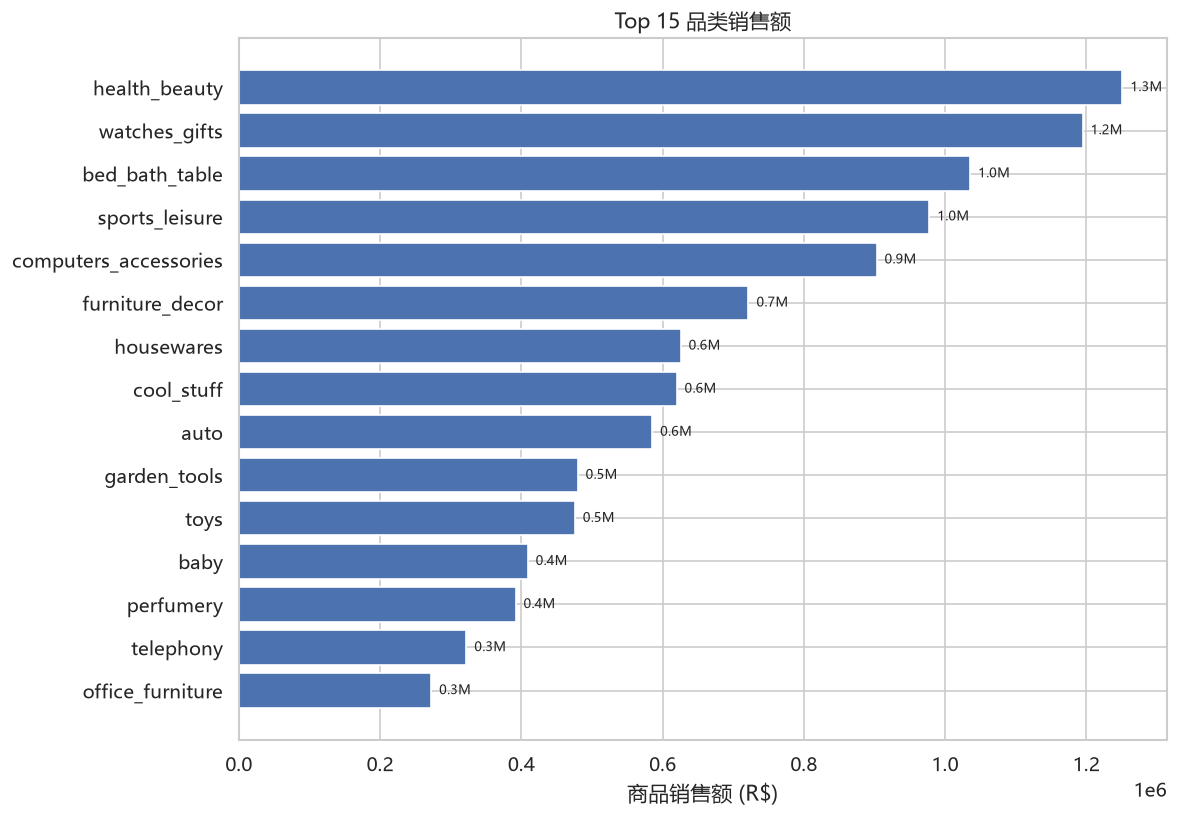

In [3]:
top15 = sales.nlargest(15, "total_sales").sort_values("total_sales")

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top15["category"], top15["total_sales"], color="#4C72B0")
ax.set_xlabel("商品销售额 (R$)")
ax.set_title("Top 15 品类销售额")
for bar, v in zip(bars, top15["total_sales"]):
    ax.text(v, bar.get_y() + bar.get_height() / 2, f"  {v/1e6:.1f}M", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### 观察
- 销售额最高的品类是health_beauty
- 逐级头部品类之间差距不大


## 3. 图 2：品类帕累托（80/20）

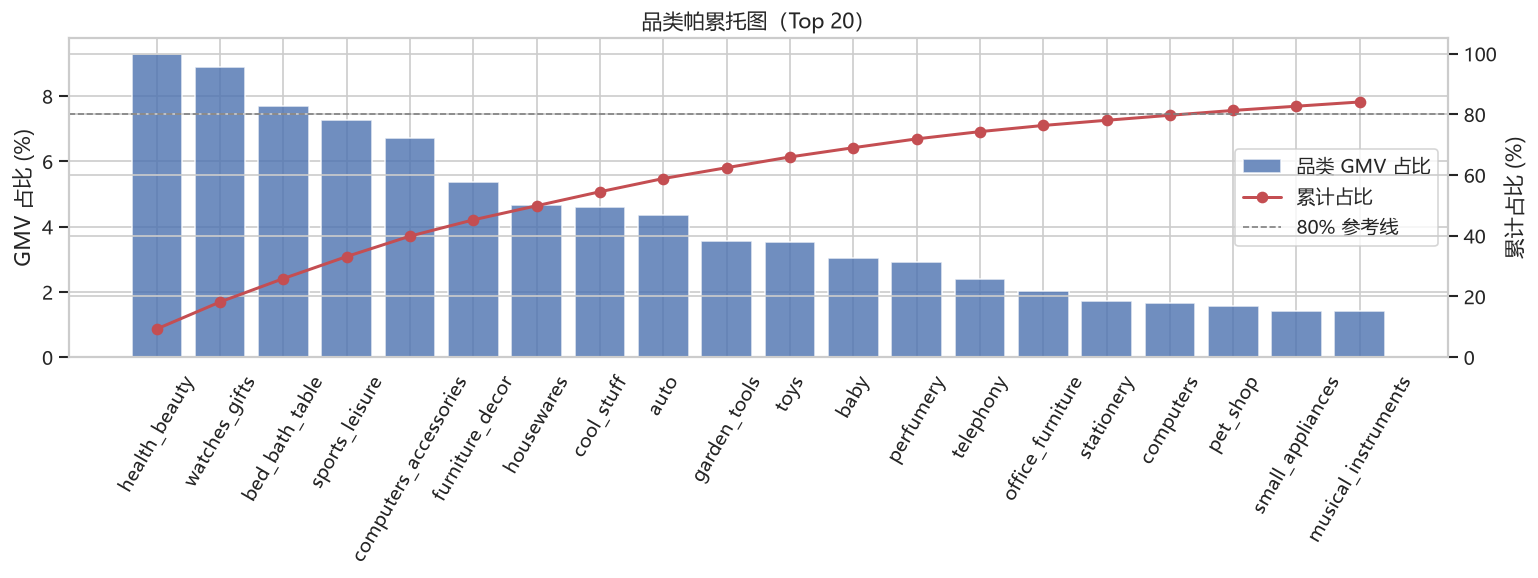

覆盖 80% 销售额所需品类数（在 Top20 内）: 18


In [4]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(pareto["category"], pareto["gmv_pct"], color="#4C72B0", alpha=0.8, label="品类 GMV 占比")
ax.set_ylabel("GMV 占比 (%)")
ax.tick_params(axis="x", rotation=60)

ax2 = ax.twinx()
ax2.plot(pareto["category"], pareto["cumulative_pct"], color="#C44E52", marker="o", lw=1.8, label="累计占比")
ax2.axhline(80, color="gray", ls="--", lw=1, label="80% 参考线")
ax2.set_ylabel("累计占比 (%)")
ax2.set_ylim(0, 105)

ax.set_title("品类帕累托图（Top 20）")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right")

plt.tight_layout()
plt.show()

hit = pareto.loc[pareto["cumulative_pct"] >= 80, "rn"]
print("覆盖 80% 销售额所需品类数（在 Top20 内）:", int(hit.min()) if len(hit) else "Top20 未达到 80%")

### 观察
- 前18个品类贡献了 80% 销售额， 符合二八定律
- 收入集中度较高，对平台意味着
- 风险：头部品类的供应链波动风险。‘长尾’的运营成本，降低投入产出比（ROI）
- 机会：将‘长尾’品类进行合并，集中资源。交叉销售红利，分析客户购买习惯，提升客单价。


## 4. 图 3：Top 5 品类月度销售额趋势

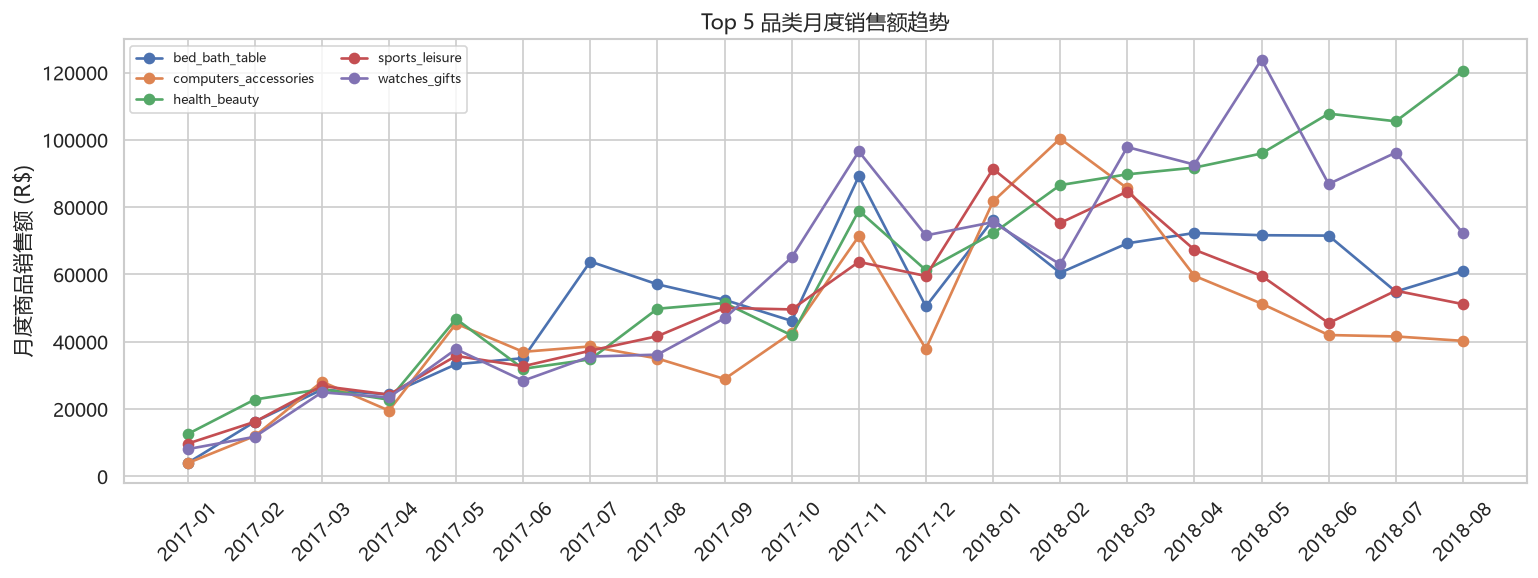

In [5]:
pivot = monthly_cat.pivot(index="month", columns="category", values="monthly_gmv").sort_index()

fig, ax = plt.subplots(figsize=(13, 5))
for col in pivot.columns:
    ax.plot(pivot.index, pivot[col], marker="o", lw=1.6, label=col)
ax.set_ylabel("月度商品销售额 (R$)")
ax.set_title("Top 5 品类月度销售额趋势")
ax.tick_params(axis="x", rotation=45)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### 观察
- health_beauty在稳定上升,剩下四个分别在2017-11至2018-5到达峰值后衰退
- 2017-11 的峰值是普涨


## 5. 各品类 Top 单品（销售额 Top 15）

In [6]:
top_products.nlargest(15, "item_revenue")[["category", "product_id", "item_revenue", "sold_qty"]]

,category,product_id,item_revenue,sold_qty
211,health_beauty,bb50f2e236e5eea0100680137654686c,63885.00,195
212,health_beauty,6cdd53843498f92890544667809f1595,54730.20,156
66,computers,d6160fb7873f184099d9bc95e30376af,48899.34,35
71,computers_accessories,d1c427060a0f73f6b889a5c7c61f2ac4,46916.51,341
35,bed_bath_table,99a4788cb24856965c36a24e339b6058,42938.66,487
72,computers_accessories,3dd2a17168ec895c781a9191c1e95ad7,41082.60,274
30,baby,25c38557cf793876c5abdd5931f922db,38907.32,38
96,cool_stuff,5f504b3a1c75b73d6151be81eb05bdc9,37733.90,63
348,watches_gifts,53b36df67ebb7c41585e8d54d6772e08,37683.42,323
191,furniture_decor,aca2eb7d00ea1a7b8ebd4e68314663af,37608.90,527
